<a href="https://colab.research.google.com/github/AfraazUlHaque/Non-Linear-SVM/blob/main/iris_NLSVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Test Accuracy: 88.0 %


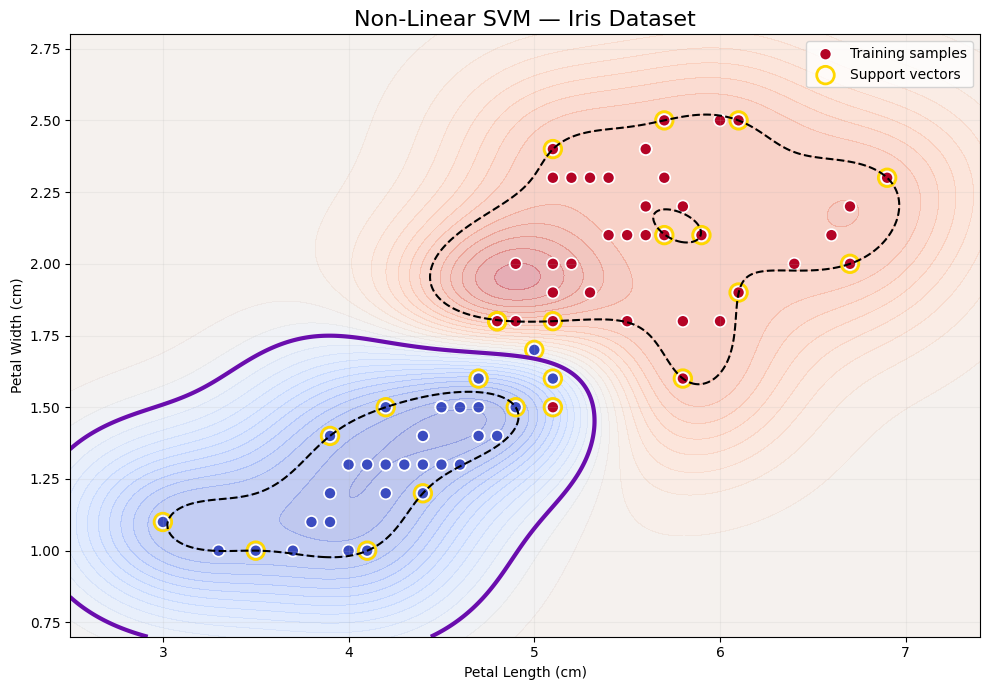

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1. Load real Iris dataset
iris = load_iris()

# Select two species:
# Versicolor (1) and Virginica (2)
mask = iris.target != 0

# Use petal length and petal width
X = iris.data[mask, 2:4]
y = iris.target[mask]

# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# 3. Non-linear SVM
model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1, gamma=2)
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Test Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# 4. Create grid
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.3, X[:, 1].max() + 0.3

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Decision function for binary classification
Z = model.decision_function(grid).reshape(xx.shape)

# 5. Plot decision regions and boundary
plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, Z,
    levels=30,
    cmap="coolwarm",
    alpha=0.35
)

# Dashed margins and solid decision boundary
plt.contour(
    xx, yy, Z,
    levels=[-1, 0, 1],
    colors=["black", "#6A0DAD", "black"],
    linestyles=["--", "-", "--"],
    linewidths=[1.5, 3, 1.5]
)

# Plot training samples
plt.scatter(
    X_train[:, 0], X_train[:, 1],
    c=y_train,
    cmap="coolwarm",
    s=75,
    edgecolors="white",
    linewidths=1.2,
    label="Training samples"
)

# Highlight support vectors
scaler = model.named_steps["standardscaler"]
svc = model.named_steps["svc"]

sv = scaler.inverse_transform(svc.support_vectors_)

plt.scatter(
    sv[:, 0], sv[:, 1],
    s=160,
    facecolors="none",
    edgecolors="gold",
    linewidths=2,
    label="Support vectors"
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Non-Linear SVM — Iris Dataset", fontsize=16)

plt.legend()
plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()